# Week 5 experimental — disease-labelled architecture comparison

**Question.** Can alternative 1-D architectures improve selected pediatric CVD-code prediction over the preserved Week 4 CNN and Week 5 ResNet checkpoints? The positive target is an exact match to any of the 19 selected strings in `Data/DiseaseCode.csv` within the semicolon-separated `ICD-10 code` field. A negative record has **none of these selected codes**; it is not necessarily healthy, CVD-free, or normal on ECG. ECG diagnostic statements are never used as targets.

**Candidates, chosen before training.** (1) A compact depthwise-separable temporal convolution network (TCN) with exponentially dilated residual blocks and global mean/max pooling. Its larger temporal context and modest parameter count may help with recurrent ECG morphology and rhythm. (2) The existing multi-scale ResNet-1D architecture from `NoteBooks/Week8/ExperimentB/models.py`, trained *afresh* on the corrected target; its parallel 7/15/31-sample kernels test whether different local scales help. Existing Week 8 results are not used. Neither architecture is presumed superior.

**Fair comparison.** The first 5,000 samples at 500 Hz, the same per-present-lead z-score, anatomical 12-slot lead mapping, patient split, batch size, optimizer, seed, unweighted loss, validation set, and 0.5 decision threshold are shared. Saved Week 4 and Week 5 checkpoints are re-evaluated on the same validation loader and checked against their original confusion matrices. Each candidate trains up to 8 epochs with early stopping after 3 epochs without improvement; its retained epoch minimizes *unweighted validation cross entropy*. The **experimental winner** is the candidate with highest validation average precision (AP), ties by sensitivity then AUROC. A **broad validation improvement over the selected Week 5 unweighted ResNet** requires higher AP, AUROC no lower, sensitivity no lower, F1 no lower, and specificity at least 0.5. Metrics and confusion matrices are reported regardless. This selection and all uncertainty estimates use the same validation data, so they are exploratory, not test evidence.

**Test freeze.** Only patient IDs are read to allocate the historical 70/15/15 split. ICD labels, signals, and outcomes are constructed and loaded for training and validation patients only. The reserved test patients are never scored, profiled, or used to choose models. All new outputs are saved in this directory.

In [1]:
from pathlib import Path
import csv, os, random, sys, platform, importlib.util, json, shutil
import numpy as np, pandas as pd, wfdb, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)
from IPython.display import display

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').is_file())
OUT=ROOT/'NoteBooks/Week5/experimental'; RECORDS=ROOT/'Child_ECG/Child_ecg'
W4=ROOT/'NoteBooks/Week4'; W5=ROOT/'NoteBooks/Week5'
SEED=42; FS=500; N_SAMPLES=5000; BATCH_SIZE=32; MAX_EPOCHS=8; PATIENCE=3; LR=3e-4; WEIGHT_DECAY=1e-4
assert Path(sys.executable).resolve()==(ROOT/'venv/bin/python').resolve(), 'Use existing project venv.'
print('Python',platform.python_version(),sys.executable)
print('Torch',torch.__version__,'compiled CUDA',torch.version.cuda,'CUDA available',torch.cuda.is_available())
assert torch.cuda.is_available(), 'Stop before training if CUDA is unavailable in the actual notebook kernel.'
DEVICE=torch.device('cuda');print('GPU',torch.cuda.get_device_name(0))
print('WFDB',wfdb.__version__,'pandas',pd.__version__,'NumPy',np.__version__)
torch.set_num_threads(min(4,os.cpu_count() or 1))
def seed_all():
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic=True;torch.backends.cudnn.benchmark=False
seed_all()

Python 3.13.5 /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python
Torch 2.6.0+cu124 compiled CUDA 12.4 CUDA available True
GPU NVIDIA GeForce RTX 3060 Laptop GPU
WFDB 4.3.1 pandas 2.3.3 NumPy 2.5.2


## Cohort, split, and target audit

The first CSV pass reads only patient IDs. The second pass skips held-out patients *before* inspecting any diagnosis or waveform fields. The split matches the earlier sorted-ID, seed-42 patient partition. Multiple selected ICD codes can occur on one record. Qualifiers such as `(FO) Q21.1` remain part of exact tokens.

In [2]:
metadata_path=ROOT/'Data/AttributesDictionary.csv'
with metadata_path.open(newline='') as handle:
    reader=csv.DictReader(handle)
    patient_ids=sorted({row['Patient_ID'] for row in reader})
random.Random(SEED).shuffle(patient_ids)
n_train=int(.70*len(patient_ids));n_val=int(.15*len(patient_ids))
train_ids=set(patient_ids[:n_train]);val_ids=set(patient_ids[n_train:n_train+n_val]);heldout_ids=set(patient_ids[n_train+n_val:])
assert not (train_ids&val_ids or train_ids&heldout_ids or val_ids&heldout_ids)
disease=pd.read_csv(ROOT/'Data/DiseaseCode.csv')
selected_codes=set(disease.loc[disease['Disease Type']!='Other diseases(OD)','ICD-10 Code'].astype(str).str.strip())
assert len(selected_codes)==19
def icd_tokens(value):return [x.strip().strip("'\"").strip() for x in value.split(';') if x.strip()]
train_rows=[];val_rows=[]
with metadata_path.open(newline='') as handle:
    for row in csv.DictReader(handle):
        pid=row['Patient_ID']
        if pid in heldout_ids:continue  # No test ICD field is accessed.
        assert row['Filename'].split('/')[-2]==pid
        row['target']=int(bool(set(icd_tokens(row['ICD-10 code']))&selected_codes))
        (train_rows if pid in train_ids else val_rows).append(row)
train_df=pd.DataFrame(train_rows);val_df=pd.DataFrame(val_rows)
for frame in [train_df,val_df]:
    frame['target']=frame.target.astype(int)
    frame['Lead']=frame.Lead.astype(int)
    frame['Sampling_point']=frame.Sampling_point.astype(int)
    frame['age_years']=frame.Age.str.extract(r'^(\d+)d$')[0].astype(float)/365.25
    assert frame.age_years.notna().all()
assert (len(train_df),len(val_df))==(9943,2169)
assert (train_df.target.sum(),val_df.target.sum())==(2595,583)
print('Patient counts: train',len(train_ids),'validation',len(val_ids),'reserved',len(heldout_ids))
print('Record counts: train',len(train_df),'validation',len(val_df))
print('Positive prevalence: train',round(train_df.target.mean(),4),'validation',round(val_df.target.mean(),4))
profile=pd.concat([train_df,val_df],ignore_index=True)
print('Lead counts train+validation',profile.Lead.value_counts().sort_index().to_dict())
print('Age years quantiles',profile.age_years.quantile([0,.25,.5,.75,1]).round(2).to_dict())
print('Duration seconds quantiles',(profile.Sampling_point/FS).quantile([0,.25,.5,.75,1]).to_dict())
print('Records longer than 10 s',int((profile.Sampling_point>N_SAMPLES).sum()))
print('Train+validation selected-code frequencies can overlap:')
code_frequency={code:sum(code in icd_tokens(value) for value in profile['ICD-10 code']) for code in sorted(selected_codes)}
display(pd.Series(code_frequency,name='records').sort_values(ascending=False).to_frame())
profile_summary=pd.DataFrame([{'split':'train','patients':len(train_ids),'records':len(train_df),'positive_records':int(train_df.target.sum()),'positive_prevalence':train_df.target.mean()},
                              {'split':'validation','patients':len(val_ids),'records':len(val_df),'positive_records':int(val_df.target.sum()),'positive_prevalence':val_df.target.mean()}])
profile_summary.to_csv(OUT/'cohort_summary.csv',index=False)

Patient counts: train 8150 validation 1746 reserved 1747
Record counts: train 9943 validation 2169
Positive prevalence: train 0.261 validation 0.2688
Lead counts train+validation {9: 1579, 12: 10533}
Age years quantiles {0.0: 0.0, 0.25: 4.25, 0.5: 8.59, 0.75: 12.38, 1.0: 14.99}
Duration seconds quantiles {0.0: 5.0, 0.25: 21.0, 0.5: 30.0, 0.75: 30.0, 1.0: 120.0}
Records longer than 10 s 12092
Train+validation selected-code frequencies can overlap:


,records
Q21.0,919
Q21.1,798
(FO) Q21.1,524
Q25.0,294
(V) I40.0,273
M30.3,159
I51.4,141
Q21.3,82
(F) I40.0,80
(OSD) Q21.1,75


## WFDB preprocessing and frozen baseline reproduction

The loader matches the Week 5 disease-labelled notebook: read the first 10 seconds (pad shorter records), map header lead names into `[I, II, III, AVR, AVL, AVF, V1, V2, V3, V4, V5, V6]`, z-score each observed lead in its observed window, and leave absent leads as zeros. Nine-lead records lack V2/V4/V6. This removes absolute voltage information and may expose acquisition configuration; subgroup analysis below examines the resulting disparities. Validation is record-level, though patients are separated across partitions.

In [3]:
LEADS=['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']
LEAD_INDEX={lead:i for i,lead in enumerate(LEADS)}
length_by_file=dict(zip(profile.Filename,profile.Sampling_point))
class CVDRecordDataset(Dataset):
    def __init__(self,frame):self.frame=frame[['Filename','target']].reset_index(drop=True)
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        signal,fields=wfdb.rdsamp(str(RECORDS/row.Filename),sampto=min(N_SAMPLES,int(length_by_file[row.Filename])))
        assert fields['fs']==FS and np.isfinite(signal).all()
        output=np.zeros((12,N_SAMPLES),dtype=np.float32)
        for j,lead in enumerate(fields['sig_name']):
            key=lead.upper();assert key in LEAD_INDEX
            x=signal[:,j].astype(np.float32);std=x.std()
            output[LEAD_INDEX[key],:len(x)]=(x-x.mean())/std if std>1e-8 else 0
        return torch.from_numpy(output),int(row.target)
train_data=CVDRecordDataset(train_df);val_data=CVDRecordDataset(val_df)
train_loader=DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True,num_workers=2)
val_loader=DataLoader(val_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=2)
def import_module(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
    return module
SimpleECGModel=import_module('week4_original_arch',W4/'pytorch_starter.py').SimpleECGModel
ResNet1D=import_module('week5_original_arch',W5/'models.py').ResNet1D
MultiScaleResNet1D=import_module('week8_multiscale_arch',ROOT/'NoteBooks/Week8/ExperimentB/models.py').MultiScaleResNet1D

def metrics(y,p):
    pred=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),
                precision=precision_score(y,pred,zero_division=0),sensitivity=recall_score(y,pred,zero_division=0),
                specificity=tn/(tn+fp),f1=f1_score(y,pred,zero_division=0),
                auroc=roc_auc_score(y,p),average_precision=average_precision_score(y,p),
                tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

def evaluate_model(model,loader):
    model.eval();ys=[];ps=[];total=0.
    with torch.no_grad():
        for x,y in loader:
            x=x.to(DEVICE);y=y.to(DEVICE);logits=model(x)
            total+=F.cross_entropy(logits,y).item()*len(y)
            ys.extend(y.cpu().tolist());ps.extend(torch.softmax(logits,dim=1)[:,1].cpu().tolist())
    return total/len(loader.dataset),np.asarray(ys),np.asarray(ps)

baseline_paths={
 'week4_cnn':W4/'Week4_CVD_Binary_CNN_best.pth',
 'week5_resnet_unweighted':W5/'disease_labelled/resnet_unweighted_best.pth',
 'week5_resnet_weighted':W5/'disease_labelled/resnet_weighted_best.pth'}
baselines={}
for name,path in baseline_paths.items():
    net=SimpleECGModel(2) if name=='week4_cnn' else ResNet1D(2)
    net=net.to(DEVICE)
    if name=='week4_cnn':
        with torch.no_grad():net(torch.zeros(1,12,N_SAMPLES,device=DEVICE))
    saved=torch.load(path,map_location=DEVICE,weights_only=False)
    assert saved['lead_order']==LEADS and saved['input_samples']==N_SAMPLES
    net.load_state_dict(saved['model_state_dict'])
    loss,y,p=evaluate_model(net,val_loader)
    baselines[name]={'loss':loss,'y':y,'p':p,'metrics':metrics(y,p),'epoch':saved['epoch']}
    print(name,'epoch',saved['epoch'],'validation loss',round(loss,4),'confusion',
          [baselines[name]['metrics'][k] for k in ['tn','fp','fn','tp']])
    del net
assert [baselines['week4_cnn']['metrics'][k] for k in ['tn','fp','fn','tp']]==[1433,153,401,182]
assert [baselines['week5_resnet_unweighted']['metrics'][k] for k in ['tn','fp','fn','tp']]==[1511,75,323,260]
assert [baselines['week5_resnet_weighted']['metrics'][k] for k in ['tn','fp','fn','tp']]==[1232,354,194,389]
assert np.array_equal(baselines['week4_cnn']['y'],baselines['week5_resnet_unweighted']['y'])
print('Baseline validation records and predictions reproduced exactly.')

week4_cnn epoch 1 validation loss 0.5526 confusion [1433, 153, 401, 182]


week5_resnet_unweighted epoch 7 validation loss 0.4359 confusion [1511, 75, 323, 260]


week5_resnet_weighted epoch 1 validation loss 0.5338 confusion [1232, 354, 194, 389]
Baseline validation records and predictions reproduced exactly.


## Candidate 1: compact dilated temporal CNN

A shared 12-lead convolutional stem reduces length by four, followed by residual depthwise-separable temporal blocks with dilations 1, 2, 4, 8, 16, and 32. Global mean and max pooling provide both pervasive and focal summaries. No metadata or lead count is fed explicitly. The model is intentionally smaller than the Week 5 ResNet; wider context, not parameter count, is the hypothesis.

In [4]:
class DilatedDepthwiseBlock(nn.Module):
    def __init__(self,channels,dilation):
        super().__init__()
        self.dw=nn.Conv1d(channels,channels,kernel_size=7,padding=3*dilation,dilation=dilation,groups=channels,bias=False)
        self.pw=nn.Conv1d(channels,channels,kernel_size=1,bias=False)
        self.bn=nn.BatchNorm1d(channels)
        self.relu=nn.ReLU()
    def forward(self,x):return self.relu(x+self.bn(self.pw(self.dw(x))))
class CompactDilatedTCN(nn.Module):
    def __init__(self,num_classes=2):
        super().__init__()
        self.stem=nn.Sequential(nn.Conv1d(12,64,15,stride=2,padding=7,bias=False),nn.BatchNorm1d(64),nn.ReLU(),
                                nn.MaxPool1d(3,stride=2,padding=1))
        self.blocks=nn.Sequential(*[DilatedDepthwiseBlock(64,d) for d in [1,2,4,8,16,32]])
        self.fc=nn.Linear(128,num_classes)
    def forward(self,x):
        x=self.blocks(self.stem(x))
        return self.fc(torch.cat([x.mean(-1),x.amax(-1)],dim=1))
for name,cls in [('compact_dilated_tcn',CompactDilatedTCN),('multiscale_resnet',MultiScaleResNet1D)]:
    m=cls();print(name,'trainable parameters',sum(p.numel() for p in m.parameters()));del m

compact_dilated_tcn trainable parameters 39938
multiscale_resnet trainable parameters 618050


## Sequential training: TCN, then multi-scale ResNet

Both candidates start from the same seed and use Adam, learning rate 3e-4, weight decay 1e-4, batch size 32, unweighted cross entropy, and the same loader. The second run starts only after the first finishes. Histories are written after every epoch; best validation-loss checkpoints are retained separately. No test loader exists.

In [5]:
def train_candidate(name,factory):
    seed_all();model=factory(num_classes=2).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    history=[];best_loss=float('inf');best_epoch=None;without_improvement=0
    history_path=OUT/f'{name}_history.csv';checkpoint=OUT/f'{name}_best.pth'
    for epoch in range(1,MAX_EPOCHS+1):
        model.train();train_total=0.
        for x,y in train_loader:
            x=x.to(DEVICE);y=y.to(DEVICE)
            optimizer.zero_grad();logits=model(x);loss=F.cross_entropy(logits,y)
            loss.backward();optimizer.step();train_total+=loss.item()*len(y)
        train_loss=train_total/len(train_data)
        val_loss,y,p=evaluate_model(model,val_loader);m=metrics(y,p)
        history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
                        'val_accuracy':m['accuracy'],'val_sensitivity':m['sensitivity'],
                        'val_specificity':m['specificity'],'val_f1':m['f1'],
                        'val_auroc':m['auroc'],'val_average_precision':m['average_precision']})
        pd.DataFrame(history).to_csv(history_path,index=False)
        if val_loss<best_loss-1e-5:
            best_loss=val_loss;best_epoch=epoch;without_improvement=0
            torch.save({'model_state_dict':model.state_dict(),'architecture':name,'epoch':epoch,
                        'validation_loss':val_loss,'seed':SEED,'selected_codes':sorted(selected_codes),
                        'lead_order':LEADS,'input_samples':N_SAMPLES,
                        'batch_size':BATCH_SIZE,'lr':LR,'weight_decay':WEIGHT_DECAY,
                        'selection':'minimum unweighted validation cross entropy'},checkpoint)
        else:without_improvement+=1
        print(f'{name} epoch {epoch}: train loss {train_loss:.4f} val loss {val_loss:.4f} '
              f'AP {m["average_precision"]:.4f} AUROC {m["auroc"]:.4f} '
              f'sens {m["sensitivity"]:.4f} spec {m["specificity"]:.4f}',flush=True)
        if without_improvement>=PATIENCE:break
    saved=torch.load(checkpoint,map_location=DEVICE,weights_only=False)
    model.load_state_dict(saved['model_state_dict'])
    val_loss,y,p=evaluate_model(model,val_loader)
    del model;torch.cuda.empty_cache()
    return {'checkpoint':checkpoint,'history':history_path,'epoch':best_epoch,'loss':val_loss,
            'y':y,'p':p,'metrics':metrics(y,p)}

experiments={}
experiments['compact_dilated_tcn']=train_candidate('compact_dilated_tcn',CompactDilatedTCN)
print('First candidate complete; starting second candidate.',flush=True)
experiments['multiscale_resnet']=train_candidate('multiscale_resnet',MultiScaleResNet1D)
print('Both candidates complete.',flush=True)

compact_dilated_tcn epoch 1: train loss 0.5633 val loss 0.5207 AP 0.5831 AUROC 0.7462 sens 0.1887 spec 0.9805


compact_dilated_tcn epoch 2: train loss 0.4853 val loss 0.4815 AP 0.6098 AUROC 0.7717 sens 0.3499 spec 0.9521


compact_dilated_tcn epoch 3: train loss 0.4550 val loss 0.4878 AP 0.6052 AUROC 0.7647 sens 0.4511 spec 0.9023


compact_dilated_tcn epoch 4: train loss 0.4326 val loss 0.4883 AP 0.6213 AUROC 0.7762 sens 0.5283 spec 0.8657


compact_dilated_tcn epoch 5: train loss 0.4084 val loss 0.4998 AP 0.6261 AUROC 0.7765 sens 0.5506 spec 0.8474


First candidate complete; starting second candidate.


... (5 outputs left out)

multiscale_resnet epoch 6: train loss 0.4365 val loss 0.4417 AP 0.6823 AUROC 0.8077 sens 0.4460 spec 0.9496


multiscale_resnet epoch 7: train loss 0.4271 val loss 0.4539 AP 0.6963 AUROC 0.8143 sens 0.4357 spec 0.9540


multiscale_resnet epoch 8: train loss 0.4181 val loss 0.4536 AP 0.6676 AUROC 0.7937 sens 0.4666 spec 0.9344


Both candidates complete.


## Comparable validation results and selection

All rows use the same ordered validation records and exact preprocessing. The fixed 0.5 threshold determines confusion matrices and sensitivity/specificity/F1. Continuous probabilities determine AUROC and AP. The experimental winner is the higher-AP candidate, ties by sensitivity then AUROC. We separately assess whether it improves broadly over the selected Week 5 unweighted ResNet. Because the validation set selected epochs and architectures, observed differences may be optimistic.

In [6]:
all_runs={**baselines,**experiments}
assert all(np.array_equal(run['y'],val_df.target.to_numpy()) for run in all_runs.values())
rows=[]
for name,run in all_runs.items():rows.append({'model':name,'epoch':run['epoch'],'val_loss':run['loss'],**run['metrics']})
comparison=pd.DataFrame(rows).set_index('model')
metric_cols=['epoch','val_loss','accuracy','balanced_accuracy','precision','sensitivity','specificity','f1','auroc','average_precision','tn','fp','fn','tp']
display(comparison[metric_cols].round(4))
comparison.to_csv(OUT/'validation_comparison.csv')
validation_predictions=pd.DataFrame({'validation_index':np.arange(len(val_df)),'target':val_df.target.to_numpy(),
                                    'age_years':val_df.age_years.to_numpy(),'lead_count':val_df.Lead.to_numpy(),
                                    'patient_id':val_df.Patient_ID.to_numpy()})
for name,run in all_runs.items():validation_predictions[name+'_probability']=run['p']
validation_predictions.to_csv(OUT/'validation_predictions.csv',index=False)
experimental_winner=max(experiments,key=lambda n:(experiments[n]['metrics']['average_precision'],
                                      experiments[n]['metrics']['sensitivity'],experiments[n]['metrics']['auroc']))
w=experiments[experimental_winner]['metrics'];b=baselines['week5_resnet_unweighted']['metrics']
broad_gain=(w['average_precision']>b['average_precision'] and w['auroc']>=b['auroc']
            and w['sensitivity']>=b['sensitivity'] and w['f1']>=b['f1'] and w['specificity']>=.5)
selection={'winner':experimental_winner,'winner_checkpoint':str(experiments[experimental_winner]['checkpoint']),
           'criterion':'highest validation AP among experimental candidates; ties sensitivity then AUROC',
           'broad_gain_over_week5_unweighted_resnet':bool(broad_gain),
           'broad_gain_rule':'AP higher; AUROC, sensitivity, F1 no lower; specificity >=0.5',
           'validation_only':True,'test_evaluated':False}
with (OUT/'selection.json').open('w') as handle:json.dump(selection,handle,indent=2)
shutil.copy2(experiments[experimental_winner]['checkpoint'],OUT/'selected_experimental_best.pth')
print('Selected experimental model:',experimental_winner)
print('Broad validation improvement over Week 5 unweighted ResNet by prespecified rule:',broad_gain)
print('Original candidate checkpoints and histories retained; selection manifest saved.')

,epoch,val_loss,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,auroc,average_precision,tn,fp,fn,tp
model,,,,,,,,,,,,,,
week4_cnn,1,0.5526,0.7446,0.6079,0.5433,0.3122,0.9035,0.3965,0.6763,0.4574,1433,153,401,182
week5_resnet_unweighted,7,0.4359,0.8165,0.6993,0.7761,0.4460,0.9527,0.5664,0.8144,0.6923,1511,75,323,260
week5_resnet_weighted,1,0.5338,0.7473,0.7220,0.5236,0.6672,0.7768,0.5867,0.7971,0.6548,1232,354,194,389
compact_dilated_tcn,2,0.4815,0.7902,0.6510,0.7286,0.3499,0.9521,0.4728,0.7717,0.6098,1510,76,379,204
multiscale_resnet,5,0.4335,0.8156,0.7199,0.7205,0.5129,0.9269,0.5992,0.8192,0.6947,1470,116,284,299


Selected experimental model: multiscale_resnet
Broad validation improvement over Week 5 unweighted ResNet by prespecified rule: True
Original candidate checkpoints and histories retained; selection manifest saved.


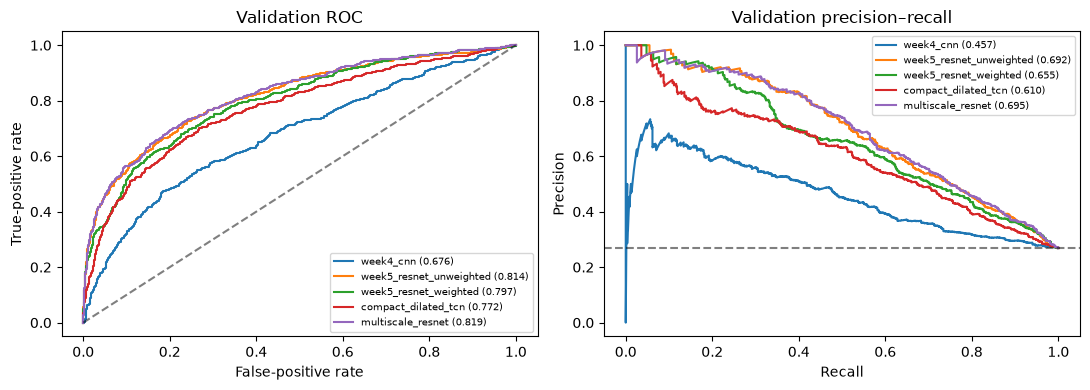

In [7]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,run in all_runs.items():
    fpr,tpr,_=roc_curve(run['y'],run['p']);precision,recall,_=precision_recall_curve(run['y'],run['p'])
    ax[0].plot(fpr,tpr,label=f'{name} ({run["metrics"]["auroc"]:.3f})')
    ax[1].plot(recall,precision,label=f'{name} ({run["metrics"]["average_precision"]:.3f})')
ax[0].plot([0,1],[0,1],'k--',alpha=.5);ax[1].axhline(val_df.target.mean(),color='k',linestyle='--',alpha=.5)
ax[0].set(xlabel='False-positive rate',ylabel='True-positive rate',title='Validation ROC')
ax[1].set(xlabel='Recall',ylabel='Precision',title='Validation precision–recall')
for a in ax:a.legend(fontsize=7)
plt.tight_layout();fig.savefig(OUT/'validation_roc_pr.png',dpi=160,bbox_inches='tight');plt.show()

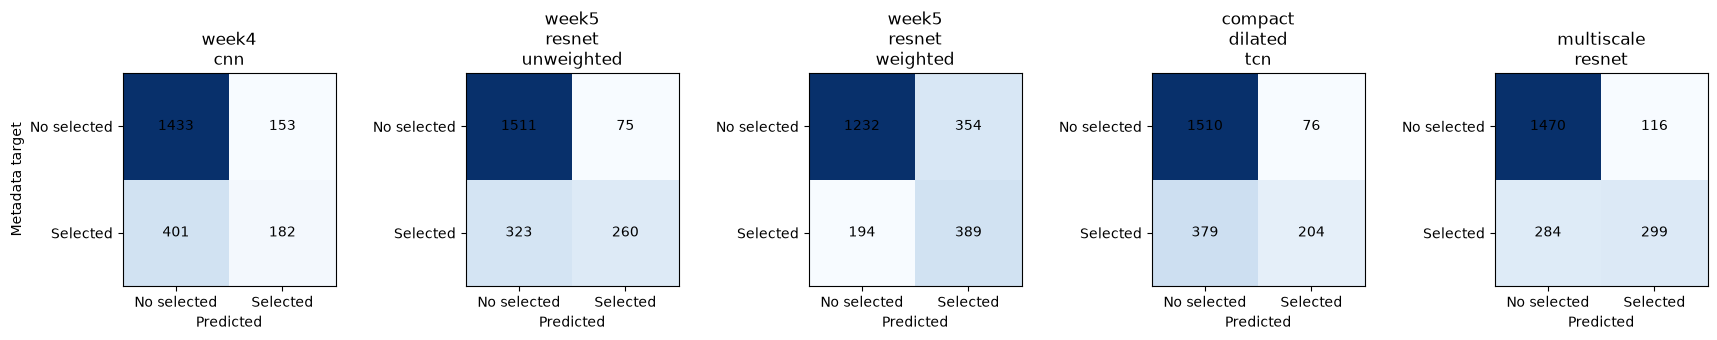

In [8]:
fig,axs=plt.subplots(1,len(all_runs),figsize=(3.5*len(all_runs),3.3))
for ax,(name,run) in zip(axs,all_runs.items()):
    m=run['metrics'];cm=np.array([[m['tn'],m['fp']],[m['fn'],m['tp']]])
    ax.imshow(cm,cmap='Blues')
    for (i,j),value in np.ndenumerate(cm):ax.text(j,i,str(value),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No selected','Selected'],
           yticklabels=['No selected','Selected'],xlabel='Predicted',title=name.replace('_','\n'))
axs[0].set_ylabel('Metadata target');plt.tight_layout()
fig.savefig(OUT/'validation_confusion_matrices.png',dpi=160,bbox_inches='tight');plt.show()

## Age and lead-count comparisons

Subgroup sample size and selected-code prevalence accompany every metric. AP is prevalence-sensitive and cannot be compared across strata without that context. Sensitivity is defined only when positives occur, specificity only when negatives occur. These are descriptive validation analyses; the sample is not independent of model selection.

In [9]:
ages=val_df.age_years.to_numpy();leads=val_df.Lead.to_numpy()
strata={'9 leads':leads==9,'12 leads':leads==12,
        'age <2y':ages<2,'age 2–<6y':(ages>=2)&(ages<6),
        'age 6–<12y':(ages>=6)&(ages<12),'age >=12y':ages>=12}
subgroup_rows=[]
for name,run in all_runs.items():
    for subgroup,mask in strata.items():
        y=run['y'][mask];p=run['p'][mask];m=metrics(y,p)
        subgroup_rows.append({'model':name,'subgroup':subgroup,'n':len(y),'positives':int(y.sum()),
                              'positive_prevalence':float(y.mean()),'accuracy':m['accuracy'],
                              'sensitivity':m['sensitivity'],'specificity':m['specificity'],
                              'f1':m['f1'],'auroc':m['auroc'],'average_precision':m['average_precision'],
                              'tn':m['tn'],'fp':m['fp'],'fn':m['fn'],'tp':m['tp']})
subgroups=pd.DataFrame(subgroup_rows)
subgroups.to_csv(OUT/'validation_subgroups.csv',index=False)
display(subgroups.round(4))

,model,subgroup,n,positives,positive_prevalence,accuracy,sensitivity,specificity,f1,auroc,average_precision,tn,fp,fn,tp
0,week4_cnn,9 leads,281,157,0.5587,0.5231,0.5159,0.5323,0.5473,0.5581,0.6276,66,58,76,81
1,week4_cnn,12 leads,1888,426,0.2256,0.7775,0.2371,0.9350,0.3248,0.6494,0.3862,1367,95,325,101
2,week4_cnn,age <2y,272,145,0.5331,0.5257,0.4621,0.5984,0.5095,0.5676,0.6074,76,51,78,67
3,week4_cnn,age 2–<6y,495,212,0.4283,0.6465,0.3255,0.8869,0.4409,0.6496,0.6016,251,32,143,69
4,week4_cnn,age 6–<12y,802,136,0.1696,0.8217,0.2647,0.9354,0.3349,0.6903,0.3530,623,43,100,36
5,week4_cnn,age >=12y,600,90,0.1500,0.8217,0.1111,0.9471,0.1575,0.5358,0.1963,483,27,80,10
6,week5_resnet_unweighted,9 leads,281,157,0.5587,0.7473,0.7261,0.7742,0.7625,0.8263,0.8679,96,28,43,114
7,week5_resnet_unweighted,12 leads,1888,426,0.2256,0.8268,0.3427,0.9679,0.4717,0.7869,0.6076,1415,47,280,146
8,week5_resnet_unweighted,age <2y,272,145,0.5331,0.7426,0.6552,0.8425,0.7308,0.8400,0.8643,107,20,50,95
9,week5_resnet_unweighted,age 2–<6y,495,212,0.4283,0.7455,0.4953,0.9329,0.6250,0.8027,0.7908,264,19,107,105


## Patient-clustered descriptive uncertainty

Resample validation **patients**, retaining all their records, to describe variability in differences between the experimental winner and the Week 5 unweighted ResNet. This is not an independent confirmation or a formal significance test because these same validation patients selected epochs and architecture. Report the 2.5th and 97.5th percentile of 300 paired resamples for AP, AUROC, sensitivity, specificity, and F1 differences.

In [10]:
rng=np.random.default_rng(SEED)
patient_to_indices={pid:np.flatnonzero(val_df.Patient_ID.to_numpy()==pid) for pid in val_df.Patient_ID.unique()}
patient_keys=np.asarray(list(patient_to_indices));winner_p=experiments[experimental_winner]['p']
reference_p=baselines['week5_resnet_unweighted']['p'];y=val_df.target.to_numpy()
bootstrap=[]
for _ in range(300):
    sampled=rng.choice(patient_keys,size=len(patient_keys),replace=True)
    ix=np.concatenate([patient_to_indices[pid] for pid in sampled])
    if len(np.unique(y[ix]))<2:continue
    wm=metrics(y[ix],winner_p[ix]);bm=metrics(y[ix],reference_p[ix])
    bootstrap.append({key:wm[key]-bm[key] for key in ['average_precision','auroc','sensitivity','specificity','f1']})
bootstrap_df=pd.DataFrame(bootstrap)
uncertainty=pd.DataFrame({'metric':bootstrap_df.columns,
                          'observed_difference':[w[k]-b[k] for k in bootstrap_df.columns],
                          'bootstrap_low_2.5':[bootstrap_df[k].quantile(.025) for k in bootstrap_df.columns],
                          'bootstrap_high_97.5':[bootstrap_df[k].quantile(.975) for k in bootstrap_df.columns]})
uncertainty.to_csv(OUT/'paired_patient_bootstrap_differences.csv',index=False)
display(uncertainty.round(4))

,metric,observed_difference,bootstrap_low_2.5,bootstrap_high_97.5
0,average_precision,0.0024,-0.0223,0.0256
1,auroc,0.0048,-0.0103,0.0191
2,sensitivity,0.0669,0.0381,0.1055
3,specificity,-0.0259,-0.0410,-0.0114
4,f1,0.0327,0.0034,0.0721


## Interpretation and research limits

**Measured comparison.** The 39,938-parameter compact dilated TCN retained epoch 2 and reached AP 0.6098, AUROC 0.7717, sensitivity 0.3499, and F1 0.4728. It improves on the Week 4 CNN but does not match the selected Week 5 ResNet. Wider temporal context with fewer parameters did not suffice in this run; no conclusion about all TCN designs follows.

The 618,050-parameter multi-scale ResNet retained epoch 5 and is the **best experimental candidate** by the prespecified AP ranking. Against the selected Week 5 unweighted ResNet, AP is 0.6947 versus 0.6923 (+0.0024), AUROC 0.8192 versus 0.8144 (+0.0048), sensitivity 0.5129 versus 0.4460 (+0.0669), and F1 0.5992 versus 0.5664 (+0.0327). Specificity falls from 0.9527 to 0.9269 (−0.0259); accuracy is 0.8156 versus 0.8165. At threshold 0.5 it finds 39 more positive validation records and flags 41 more negative records. The weighted Week 5 ResNet still has higher sensitivity (0.6672), with many more false positives. Thus the multi-scale model offers a **detection tradeoff**, not an unqualified accuracy gain.

**How much does the ranking gain mean?** The multi-scale candidate meets the stated directional improvement rule, but the patient-clustered descriptive 95% ranges for AP difference (−0.0223 to +0.0256) and AUROC difference (−0.0103 to +0.0191) include zero. The sensitivity difference is +0.0381 to +0.1055 and specificity difference −0.0410 to −0.0114. These intervals are exploratory because the same validation records selected the models. The evidence supports improved sensitivity at a specificity cost in this validation run; it does not establish a meaningful ranking improvement or generalization gain.

**Uneven subgroups.** For nine-lead validation records (n=281, positive prevalence 0.5587), the multi-scale model's sensitivity rises from 0.7261 to 0.8344, but specificity falls from 0.7742 to 0.6048 and AP falls from 0.8679 to 0.8451. For twelve-lead records (n=1,888, prevalence 0.2256), sensitivity rises from 0.3427 to 0.3944 with a smaller specificity decrease from 0.9679 to 0.9542. For ages ≥12 years (n=600, prevalence 0.1500), sensitivity falls from 0.1444 to 0.1000. The full subgroup table includes sample sizes, positive counts, prevalence, all required metrics, and confusion counts. These differences prevent a claim of consistent improvement across ages and lead configurations.

**Limits.** This is one split and one seed, with candidate and epoch selection on the same validation data. The target is a selected-code metadata label, not an independently adjudicated clinical diagnosis; negative is not necessarily disease-free. The shared first-10-second input ignores later parts of most recordings, and per-lead z-scoring removes absolute voltage. Lead availability and age are associated with labels, so shortcut learning remains possible. No test record or test outcome was used. Independent validation would be needed before a stronger claim.